TIME-SERIES INPUT, FUNCTIONAL CALIBRATION AND TWO OUTPUTS WITH A COMMON DISCREPANCY

Known experimental trajectories are \(x(t)=u_0+u_1\sin(2\pi t/T)\).
The two calibration functions are
\[
\theta_1(x,t)=a_0+a_x(x-1)+a_t(t/T-1/2),\qquad
\theta_2(t)=b_0+b_t\sin(\pi t/T).
\]
Thus five coefficients describe the unknown functions; we do not estimate an
independent parameter at every time point. This synthetic time-indexed sensor model
depends on the current input and time. It has no unmodeled dynamical state or lag.
Both outputs and the shared discrepancy have the same response units (a.u.).

\[
y_r(x,t)=\eta_r(x,t;\theta_1,\theta_2)+\delta(x,t)+\epsilon_r(t),\quad r=1,2.
\]
There is **one common δ**, added with coefficient +1 to both outputs. Its covariance
therefore contributes to the within-output and cross-output blocks. Measurement
noise is independent between sensors and observation times, with known standard deviations.

Each simulator run returns both complete curves. A single joint SVD represents both
outputs; one GP models each retained weight over the two trajectory descriptors and
five calibration coefficients. Time and output index are functional coordinates,
not additional weight-GP inputs. Emulator hyperparameters are fixed at posterior
means during calibration; their conditional prediction covariance is retained.

The common discrepancy is projected orthogonally to the **sum of the two output
sensitivities** to each calibration coefficient, with a stated quadrature measure.
This is the shared-discrepancy, finite-basis extension of the previous notebook's
Plumlee-style construction. It does not guarantee identifiability for arbitrary data.
The synthetic discrepancy is generated to satisfy the corresponding physical-model
constraint, so the generating coefficients remain a meaningful validation reference.

The code retains configured log-normal hyperparameter priors and a plug-in SVD
residual variance; it is not a numerical reproduction of all LANL defaults.
References: [LANL basis workflow](https://sepia-lanl.readthedocs.io/en/latest/forgpmsa.html),
[Plumlee (2017)](https://doi.org/10.1080/01621459.2016.1211016).

LIBRARIES AND FIGURE DEFAULTS

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

# Default figure font styling
plt.rcParams.update({
    'font.family': 'Times New Roman',
    'font.size': 11,
    'font.weight': 'bold',
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',
    'axes.titlesize': 11,
    'axes.labelsize': 11,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 11,
    'figure.titleweight': 'bold',
    'axes.prop_cycle': cycler(color=['black'] * 4, linestyle=['-', '--', ':', '-.']),
    'axes.grid': True,
    'grid.color': '0.7',
    'grid.linewidth': 0.8,
    'axes.edgecolor': 'black',
    'axes.linewidth': 1.0,
    'xtick.top': True,
    'ytick.right': True,
    'legend.frameon': False,
    'lines.linewidth': 1.5,
    'figure.facecolor': 'white',
    'figure.dpi': 300,
    'figure.figsize': (3, 2),
    'savefig.dpi': 300,
    'axes.facecolor': 'white',
})

def figure_legend(ax, ncol=3):
    """Place a frameless legend above the axes."""
    return ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02),
                     ncol=ncol, frameon=False,
                     columnspacing=0.7, handlelength=1.5, handletextpad=0.4)

rng = np.random.default_rng(2026)

from scipy.linalg import cholesky, solve_triangular, cho_solve
from scipy.interpolate import CubicSpline
from scipy.stats import qmc, rankdata, norm
from scipy.optimize import minimize
from threadpoolctl import threadpool_limits
import pandas as pd

KNOWN INPUT TRAJECTORIES AND THE TWO CALIBRATION FUNCTIONS

In [5]:
T = 1.2
time_sim = np.linspace(0.0, T, 31)
trajectory_lower = np.array([0.8, 0.10])
trajectory_upper = np.array([1.2, 0.35])
coefficient_lower = np.array([0.6, -0.4, -0.4, 0.7, -0.3])
coefficient_upper = np.array([1.4, 0.4, 0.4, 1.3, 0.3])
lower_bounds = np.r_[trajectory_lower, coefficient_lower]
upper_bounds = np.r_[trajectory_upper, coefficient_upper]
coefficient_names = ['a₀', 'aₓ', 'aₜ', 'b₀', 'bₜ']
n_coefficients, n_outputs = 5, 2
x_min, x_max = trajectory_lower[0] - trajectory_upper[1], trajectory_upper[0] + trajectory_upper[1]

def input_trajectory(trajectory, times):
    trajectory, times = np.asarray(trajectory, float), np.asarray(times, float)
    return trajectory[..., 0] + trajectory[..., 1] * np.sin(2 * np.pi * times / T)

def theta_functions(x, times, coefficients):
    x, times, coefficients = np.asarray(x, float), np.asarray(times, float), np.asarray(coefficients, float)
    if coefficients.shape != (5,):
        raise ValueError('Expected five calibration coefficients')
    theta1 = coefficients[0] + coefficients[1] * (x-1) + coefficients[2] * (times/T-0.5)
    theta2 = coefficients[3] + coefficients[4] * np.sin(np.pi * times/T)
    return theta1, theta2

def physics_model(trajectory, coefficients, times):
    times = np.asarray(times, float)
    x = input_trajectory(trajectory, times)
    theta1, theta2 = theta_functions(x, times, coefficients)
    s = times / T
    y1 = theta1 * x + theta2 * (1 - np.exp(-2*s))
    y2 = 0.5 + 0.7 * theta1 * x**2 + theta2 * (0.3 + 0.8*np.sin(np.pi*s/2))
    return np.stack((y1, y2), axis=-1)

def physical_coefficient_gradient(trajectory, times):
    x, s = input_trajectory(trajectory, times), np.asarray(times)/T
    theta1_basis = np.column_stack((np.ones_like(s), x-1, s-0.5))
    theta2_basis = np.column_stack((np.ones_like(s), np.sin(np.pi*s)))
    gradient = np.empty((len(s), 2, 5))
    gradient[:, 0, :3] = x[:, None] * theta1_basis
    gradient[:, 1, :3] = (0.7*x**2)[:, None] * theta1_basis
    gradient[:, 0, 3:] = (1-np.exp(-2*s))[:, None] * theta2_basis
    gradient[:, 1, 3:] = (0.3+0.8*np.sin(np.pi*s/2))[:, None] * theta2_basis
    return gradient

SIMULATOR DESIGN: JOINT TWO-OUTPUT CURVES AND WHOLE-RUN HOLDOUT

In [7]:
from sklearn.model_selection import train_test_split
n_sim = 120
design_unit = qmc.LatinHypercube(d=7, seed=2026).random(n_sim)
design = qmc.scale(design_unit, lower_bounds, upper_bounds)
y_curves = np.array([physics_model(row[:2], row[2:], time_sim) for row in design])
train_runs, test_runs = train_test_split(np.arange(n_sim), test_size=0.2, random_state=2026)
X_train, X_test = design_unit[train_runs], design_unit[test_runs]
# Output order: (time0,y1), (time0,y2), (time1,y1), (time1,y2), ...
y_train_raw = y_curves[train_runs].reshape(len(train_runs), -1)
y_test_raw = y_curves[test_runs].reshape(len(test_runs), -1)
assert not set(train_runs).intersection(test_runs)
print('Functional outputs (runs, times, outputs):', y_curves.shape)
print('Training/test runs:', len(train_runs), len(test_runs))

Functional outputs (runs, times, outputs): (120, 31, 2)
Training/test runs: 96 24


JOINT SVD AND RECONSTRUCTION IN PHYSICAL RESPONSE UNITS

In [9]:
svd_mean_curve = y_train_raw.mean(axis=0).reshape(len(time_sim), n_outputs)
svd_scale = np.std(y_train_raw - svd_mean_curve.ravel())
standardized_curves = (y_train_raw - svd_mean_curve.ravel()) / svd_scale
U, singular_values, Vt = np.linalg.svd(standardized_curves, full_matrices=False)
explained = np.cumsum(singular_values**2) / np.sum(singular_values**2)
variance_target = 0.9999
n_basis = int(np.searchsorted(explained, variance_target) + 1)
K_flat = Vt[:n_basis].T * singular_values[:n_basis] / np.sqrt(len(train_runs))
K_sim = K_flat.reshape(len(time_sim), n_outputs, n_basis)
weights_train = U[:, :n_basis] * np.sqrt(len(train_runs))
train_reconstruction = svd_mean_curve.ravel() + svd_scale * weights_train @ K_flat.T
weights_test_projection = ((y_test_raw - svd_mean_curve.ravel()) / svd_scale) @ np.linalg.pinv(K_flat).T
test_reconstruction = svd_mean_curve.ravel() + svd_scale * weights_test_projection @ K_flat.T
residual = (y_train_raw - train_reconstruction).reshape(len(train_runs), len(time_sim), n_outputs)
truncation_variance = np.mean(residual**2, axis=(0, 1))
_mean_spline = CubicSpline(time_sim, svd_mean_curve, axis=0)
_basis_spline = CubicSpline(time_sim, svd_scale * K_sim, axis=0)

def svd_basis_at_times(times):
    times = np.asarray(times, float)
    if times.ndim != 1 or not np.all(np.isfinite(times)) or np.any(times < 0) or np.any(times > T):
        raise ValueError('Times must be a finite one-dimensional array within [0,T]')
    return _mean_spline(times), _basis_spline(times)

assert np.allclose(weights_train.T @ weights_train / len(train_runs), np.eye(n_basis))
assert np.allclose(svd_basis_at_times(time_sim)[1], svd_scale*K_sim)
print(f'Retained basis components: {n_basis}; training variation: {explained[n_basis-1]:.4%}')
print('Training reconstruction RMSE by output:', np.sqrt(truncation_variance))
print('Held-out reconstruction RMSE:', np.sqrt(np.mean((y_test_raw-test_reconstruction)**2)))

Retained basis components: 7; training variation: 99.9916%
Training reconstruction RMSE by output: [0.0029356  0.00316737]
Held-out reconstruction RMSE: 0.0027768535985968896


COMMON DISCREPANCY BASE KERNEL AND INTEGRATION GRID

In [11]:
from numpy.polynomial.legendre import leggauss

def rbf_kernel(X1, X2, lengthscale, signal_variance):
    difference = (np.asarray(X1)[:, None, :] - np.asarray(X2)[None, :, :]) / lengthscale
    return signal_variance * np.exp(-0.5 * np.sum(difference**2, axis=2))

def discrepancy_basis(times):
    centers = np.linspace(0, 1, 5)
    D = np.exp(-0.5*((np.asarray(times)[:, None]/T-centers)/0.3)**2)
    return D / np.linalg.norm(D, axis=1, keepdims=True)

def common_base_covariance(x1, t1, x2, t2, lengthscale, variance):
    a = ((np.asarray(x1)-x_min)/(x_max-x_min))[:, None]
    b = ((np.asarray(x2)-x_min)/(x_max-x_min))[:, None]
    return rbf_kernel(a, b, lengthscale, variance) * (discrepancy_basis(t1) @ discrepancy_basis(t2).T)

def integration_grid(order_trajectory=3, order_time=12):
    nodes, w = leggauss(order_trajectory)
    a, b = np.meshgrid((nodes+1)/2, (nodes+1)/2, indexing='ij')
    trajectories = trajectory_lower + np.column_stack((a.ravel(), b.ravel()))*(trajectory_upper-trajectory_lower)
    weights_trajectory = np.outer(w/2, w/2).ravel()
    nt, wt = leggauss(order_time)
    times = (nt+1)*T/2
    return (np.repeat(trajectories, len(times), axis=0), np.tile(times, len(trajectories)),
            np.repeat(weights_trajectory, len(times))*np.tile(wt/2, len(trajectories)))

quadrature_trajectories, quadrature_times, quadrature_weights = integration_grid()
quadrature_x = input_trajectory(quadrature_trajectories, quadrature_times)

def positive_pseudoinverse(matrix):
    matrix = (matrix+matrix.T)/2
    values, vectors = np.linalg.eigh(matrix)
    active = values > max(values.max(), np.finfo(float).tiny)*1e-11
    if not np.any(active):
        raise ValueError('No supported orthogonality directions')
    return (vectors[:, active]/values[active]) @ vectors[:, active].T

SYNTHETIC OBSERVATIONS: THE SAME δ IS ADDED TO BOTH OUTPUTS

Observation table: trajectory, time, x, y1, y2
[[0.85       0.18       0.05       0.89658743 0.9578399  1.44279259]
 [0.85       0.18       0.17222222 0.99119482 1.32911108 1.87294628]
 [0.85       0.18       0.29444444 1.02992385 1.6686373  2.09265989]
 [0.85       0.18       0.41666667 0.99744737 1.74572623 2.21506396]
 [0.85       0.18       0.53888889 0.90661806 1.72001219 2.16904149]]
Common discrepancy RMS on the design measure: 0.06 a.u.


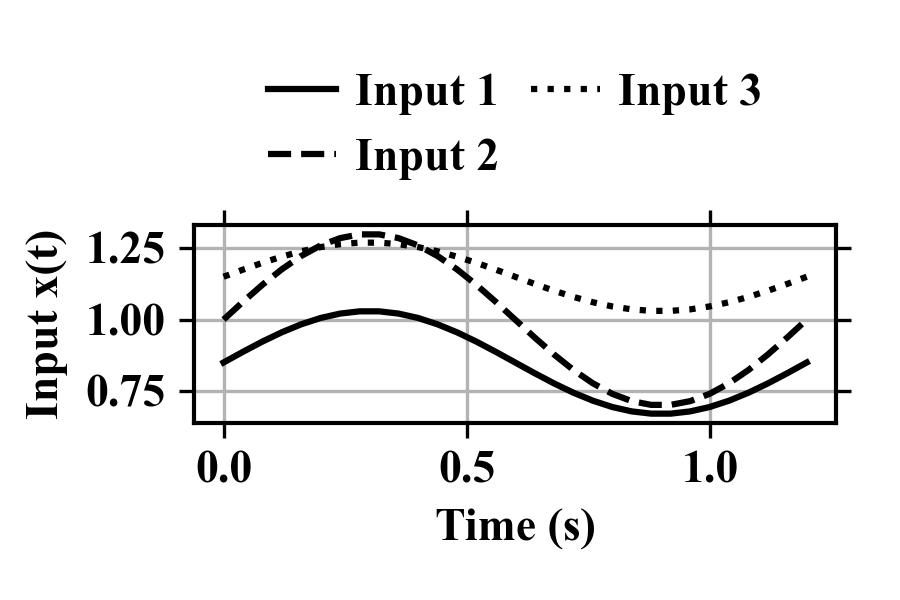

In [13]:
coefficients_true = np.array([1.0, 0.20, -0.15, 1.10, 0.12])
observation_trajectories = np.array([[0.85, 0.18], [1.00, 0.30], [1.15, 0.12]])
time_obs = np.linspace(0.05, 1.15, 10)
trajectory_obs = np.repeat(observation_trajectories, len(time_obs), axis=0)
t_obs = np.tile(time_obs, len(observation_trajectories))
x_obs = input_trajectory(trajectory_obs, t_obs)
sigma_obs = np.array([0.03, 0.03])

# Construct an orthogonal synthetic discrepancy using physical sensitivities only.
# This construction is used to generate and validate truth, never in calibration.
truth_G = physical_coefficient_gradient(quadrature_trajectories, quadrature_times).mean(axis=1)
truth_A = quadrature_weights[:, None] * truth_G
truth_K = common_base_covariance(quadrature_x, quadrature_times, quadrature_x, quadrature_times, 0.6, 1.0)
truth_H_inverse = positive_pseudoinverse(truth_A.T @ truth_K @ truth_A)
def raw_discrepancy(x, times):
    return 0.15*np.sin(2*np.pi*np.asarray(times)/T) + 0.05*(np.asarray(x)-1)*np.cos(3*np.pi*np.asarray(times)/T)
truth_projection = truth_H_inverse @ (truth_A.T @ raw_discrepancy(quadrature_x, quadrature_times))
truth_residual = raw_discrepancy(quadrature_x, quadrature_times) - truth_K @ truth_A @ truth_projection
truth_delta_scale = 0.06 / np.sqrt(np.sum(quadrature_weights * truth_residual**2))

def synthetic_discrepancy(x, times):
    cross = common_base_covariance(x, times, quadrature_x, quadrature_times, 0.6, 1.0)
    return truth_delta_scale * (raw_discrepancy(x, times) - cross @ truth_A @ truth_projection)

y_sim_true = physics_model(trajectory_obs, coefficients_true, t_obs)
delta_true = synthetic_discrepancy(x_obs, t_obs)
noise = np.random.default_rng(2026).normal(size=y_sim_true.shape) * sigma_obs
y_obs_matrix = y_sim_true + delta_true[:, None] + noise
y_obs = y_obs_matrix.ravel()
observation_noise_cov = np.diag(np.tile(sigma_obs**2, len(t_obs)))
assert np.allclose(y_obs_matrix[:, 0]-y_obs_matrix[:, 1], y_sim_true[:, 0]-y_sim_true[:, 1] + noise[:, 0]-noise[:, 1])
print('Observation table: trajectory, time, x, y1, y2')
print(np.column_stack((trajectory_obs, t_obs, x_obs, y_obs_matrix))[:5])
print('Common discrepancy RMS on the design measure: 0.06 a.u.')

fig, ax = plt.subplots(figsize=(3, 2))
for j, trajectory in enumerate(observation_trajectories):
    ax.plot(time_sim, input_trajectory(trajectory, time_sim), color='black', linestyle=['-', '--', ':'][j], label=f'Input {j+1}')
ax.set(xlabel='Time (s)', ylabel='Input x(t)')
figure_legend(ax, ncol=2)
fig.tight_layout()
plt.show()

INDEPENDENT GP PRIORS AND LIKELIHOODS FOR THE JOINT SVD WEIGHTS

In [15]:
alpha = 1e-8
training_eye = np.eye(len(X_train))
training_squared_distances = (X_train[:, None, :]-X_train[None, :, :])**2
n_emulator_inputs = X_train.shape[1]

def gp_log_likelihood(component, lengthscale, variance):
    covariance = variance*np.exp(-0.5*np.sum(training_squared_distances/lengthscale**2, axis=2)) + alpha*training_eye
    L = cholesky(covariance, lower=True, check_finite=False)
    residual = solve_triangular(L, weights_train[:, component], lower=True, check_finite=False)
    return -0.5*residual@residual - np.log(np.diag(L)).sum() - 0.5*len(X_train)*np.log(2*np.pi)

def emulator_log_target(z, component):
    if not np.all(np.isfinite(z)):
        return -np.inf
    with np.errstate(over='ignore', under='ignore', invalid='ignore', divide='ignore'):
        parameters = np.exp(z)
        if not np.all(np.isfinite(parameters)) or np.any(parameters <= 0):
            return -np.inf
        try:
            value = gp_log_likelihood(component, parameters[:-1], parameters[-1]) - 0.5*z@z
        except (ValueError, np.linalg.LinAlgError):
            return -np.inf
    return float(value) if np.isfinite(value) else -np.inf

ADAPTIVE MCMC: FOUR CHAINS, 30,000 ITERATIONS AND 10,000 BURN-IN PER CHAIN

In [17]:
def adaptive_metropolis(log_target, start, n_steps, burn_in, seed, initial_sd):
    if not 0 < burn_in < n_steps:
        raise ValueError('Require 0 < burn_in < n_steps')
    rng = np.random.default_rng(seed)
    current = np.array(start, dtype=float, copy=True)
    dimension = current.size
    logp = log_target(current)
    if not np.isfinite(logp):
        raise ValueError('Initial state must have finite log posterior')
    initial_factor = np.diag(np.broadcast_to(initial_sd, (dimension,)))
    factor = initial_factor.copy()
    chain = np.empty((n_steps, dimension))
    accepted = np.zeros(n_steps, dtype=bool)
    for i in range(n_steps):
        # The fixed 5% component maintains exploration; both proposals are symmetric.
        step_factor = initial_factor if rng.uniform() < 0.05 else factor
        proposed = current + step_factor @ rng.normal(size=dimension)
        proposed_logp = log_target(proposed)
        if np.log(rng.uniform()) < proposed_logp - logp:
            current, logp = proposed, proposed_logp
            accepted[i] = True
        chain[i] = current
        if 100 <= i + 1 <= burn_in and (i + 1) % 100 == 0:
            covariance = np.cov(chain[:i + 1], rowvar=False)
            covariance = (2.38**2 / dimension) * (covariance + 1e-6 * np.eye(dimension))
            factor = cholesky(covariance, lower=True)
    return chain, accepted

# All counts are PER CHAIN; chains are retained separately for diagnostics.
n_steps = 30000
burn_in = 10000
n_chains = 4
n_calibration_steps = 30000
calibration_burn_in = 10000

TRAINING THE WEIGHT GPs; FREEZE PHYSICAL-SCALE POSTERIOR MEANS

In [19]:
n_hypers = n_emulator_inputs + 1
emulator_log_chains = np.empty((n_basis, n_chains, n_steps, n_hypers))
emulator_accepted = np.empty((n_basis, n_chains, n_steps), dtype=bool)
with threadpool_limits(limits=1):
    for component in range(n_basis):
        target = lambda z, j=component: emulator_log_target(z, j)
        initialization = minimize(lambda z: -target(z), np.zeros(n_hypers), method='Nelder-Mead', options={'maxiter': 2000})
        center = initialization.x if np.isfinite(target(initialization.x)) else np.zeros(n_hypers)
        for chain_id in range(n_chains):
            seed = 2026 + 100*component + chain_id
            start = center + np.random.default_rng(seed).normal(0, 0.1, n_hypers)
            if not np.isfinite(target(start)):
                start = center.copy()
            chain, accepted = adaptive_metropolis(target, start, n_steps, burn_in, seed, 0.08)
            emulator_log_chains[component, chain_id] = chain
            emulator_accepted[component, chain_id] = accepted
        print(f'Weight GP {component+1}/{n_basis}: acceptance {emulator_accepted[component, :, burn_in:].mean():.3f}')
emulator_chains = np.exp(emulator_log_chains)
emulator_posterior = emulator_chains[:, :, burn_in:, :]
frozen_parameters = emulator_posterior.mean(axis=(1, 2))
print('Frozen hyperparameter matrix shape:', frozen_parameters.shape)

Weight GP 1/7: acceptance 0.181
Weight GP 2/7: acceptance 0.205
Weight GP 3/7: acceptance 0.200
Weight GP 4/7: acceptance 0.200
Weight GP 5/7: acceptance 0.199
Weight GP 6/7: acceptance 0.239
Weight GP 7/7: acceptance 0.221
Frozen hyperparameter matrix shape: (7, 8)


CONVERGENCE DIAGNOSTICS AND EMULATOR TRACE PLOTS

      parameter  posterior_mean    R_hat    ESS_bulk
GP 1: length u0        3.055737 1.000816 2662.339998
GP 1: length u1        6.909096 1.000766 1851.117011
GP 1: length a₀       21.994548 1.000788 3742.644607
GP 1: length aₓ       14.420457 1.003426 2096.992259
GP 1: length aₜ      104.129460 1.002093 2515.030108
GP 1: length b₀       70.878252 1.000964 3447.162293
GP 1: length bₜ       99.103040 1.000537 2951.753008
 GP 1: variance     1444.673771 1.000486 4272.690299
GP 2: length u0        3.145486 1.000464 2708.420940
GP 2: length u1        4.024197 1.001347 3208.093428
GP 2: length a₀       21.248899 1.001534 3287.973047
GP 2: length aₓ       10.289070 1.001887 3188.363712
GP 2: length aₜ       28.352693 1.001412 4002.190052
GP 2: length b₀       52.582672 1.001147 3412.629294
GP 2: length bₜ       78.189520 1.001962 3243.895250
 GP 2: variance     1440.989634 1.000852 4340.148991
GP 3: length u0        1.784692 1.000392 2641.682192
GP 3: length u1        3.720271 1.003053 2001.

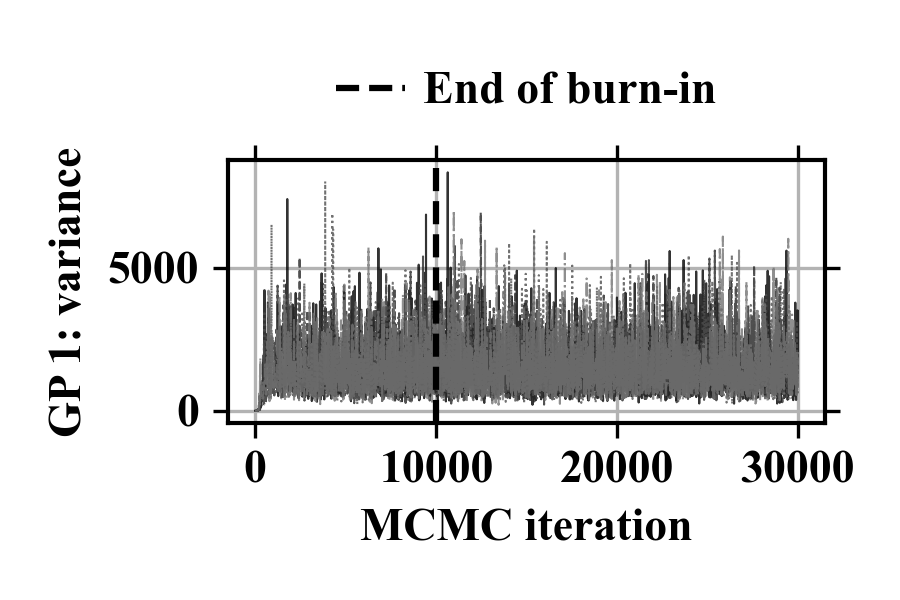

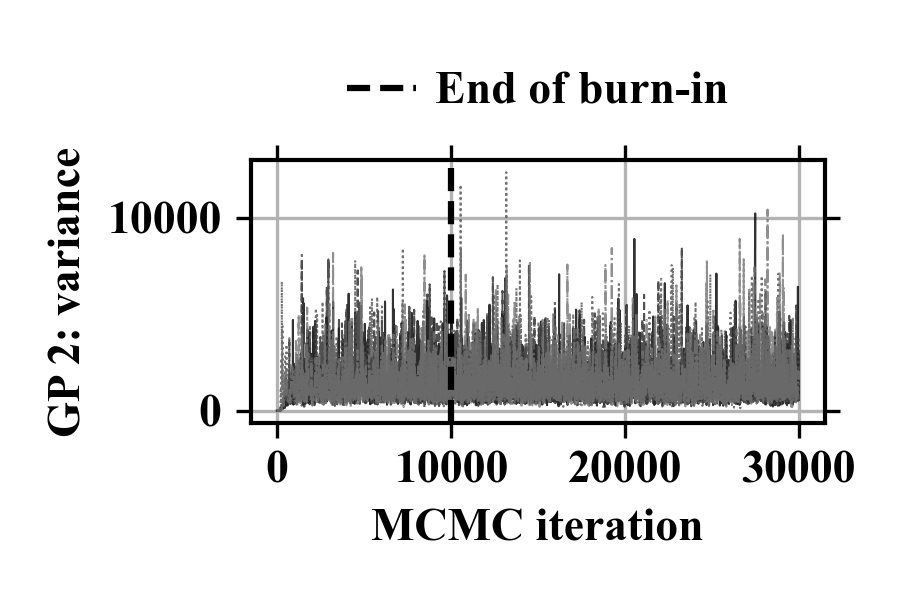

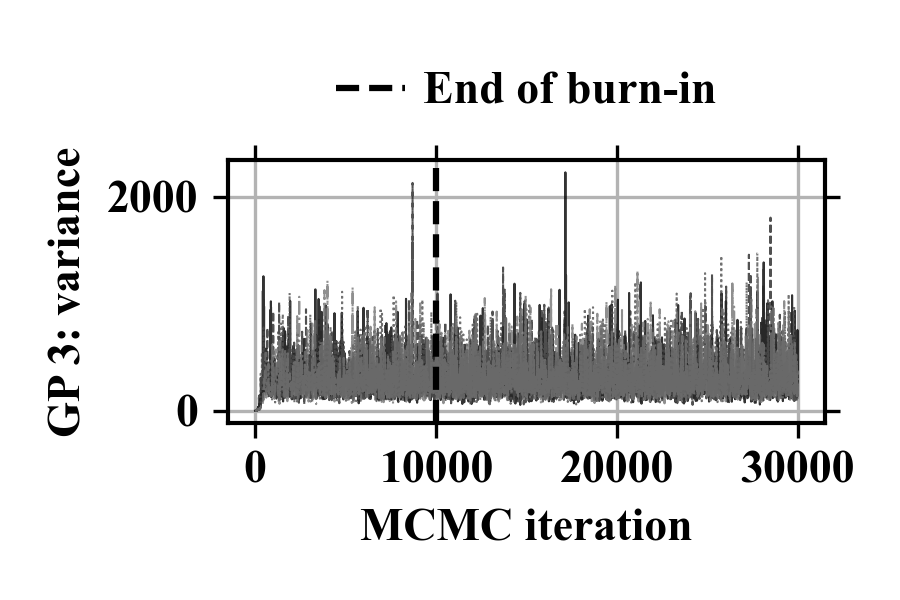

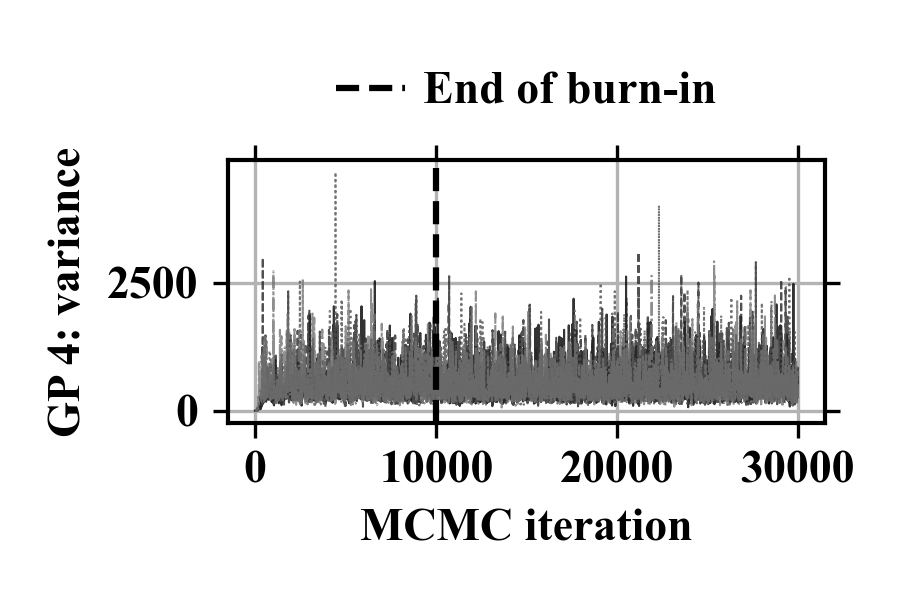

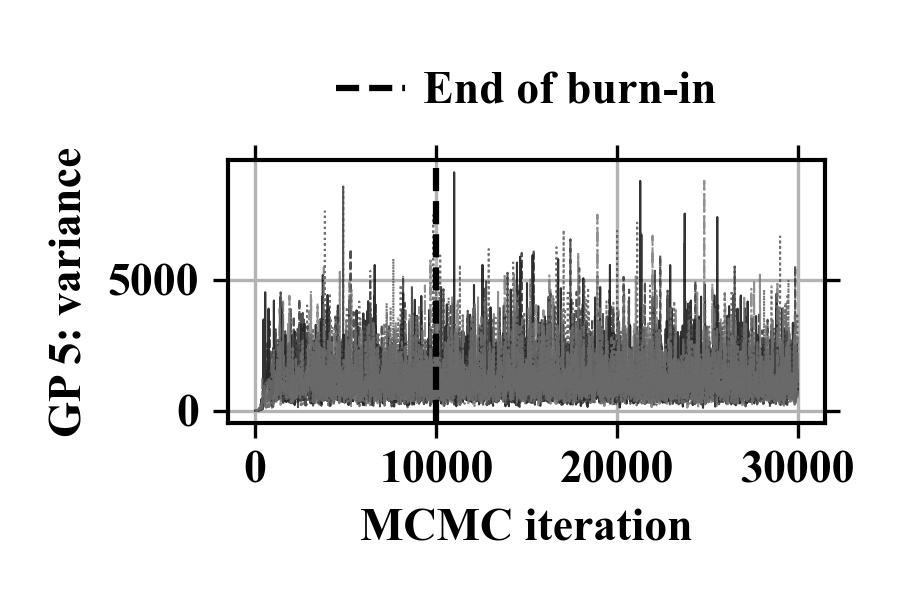

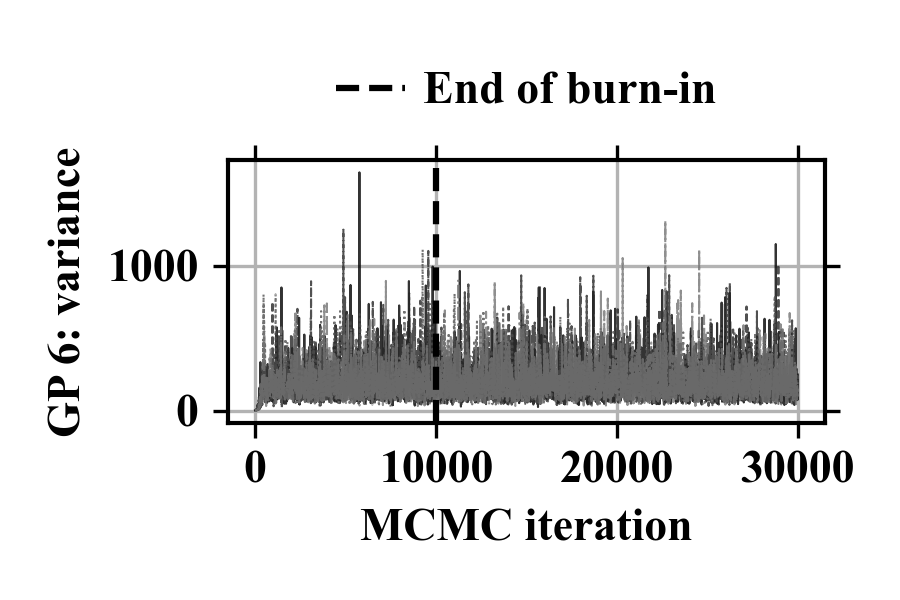

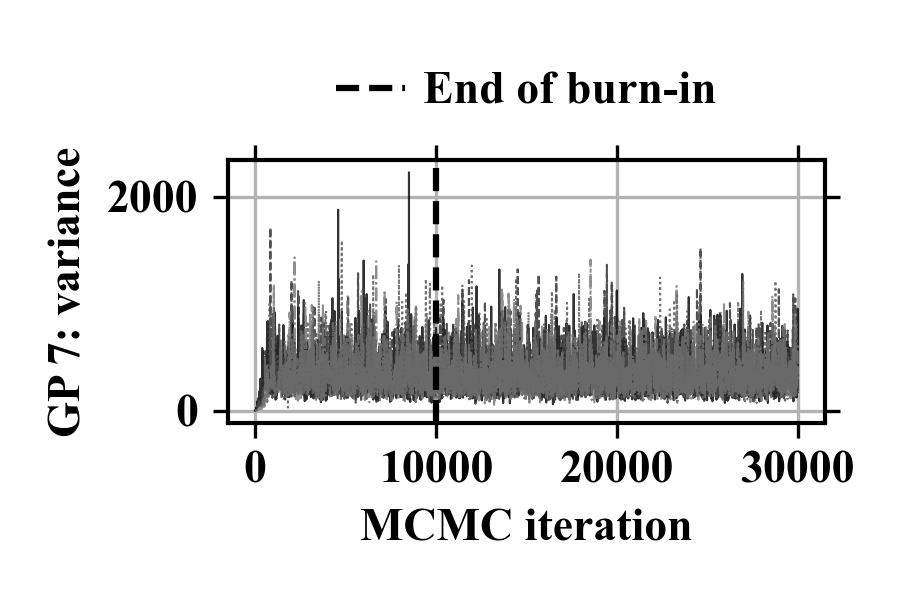

In [21]:
def _rhat(values):
    m, n = values.shape
    within = np.var(values, axis=1, ddof=1).mean()
    between = n * np.var(values.mean(axis=1), ddof=1)
    if within <= 0:
        return np.inf
    return np.sqrt(((n - 1) / n * within + between / n) / within)

def _rank_normalize(values):
    ranks = rankdata(values.ravel(), method='average')
    return norm.ppf((ranks - 0.375) / (values.size + 0.25)).reshape(values.shape)

def _bulk_ess(values):
    # Geyer's initial positive and monotone paired autocorrelation sequence.
    m, n = values.shape
    centered = values - values.mean(axis=1, keepdims=True)
    fft = np.fft.rfft(centered, n=2 * n, axis=1)
    autocov = np.fft.irfft(fft * np.conjugate(fft), n=2 * n, axis=1)[:, :n] / n
    within = np.var(values, axis=1, ddof=1).mean()
    variance = (n - 1) / n * within + np.var(values.mean(axis=1), ddof=1)
    if variance <= 0:
        return 0.0
    rho = 1 - (within - autocov.mean(axis=0)) / variance
    rho[0] = 1.0
    pairs = rho[:2 * (n // 2)].reshape(-1, 2).sum(axis=1)
    stop = np.flatnonzero(pairs <= 0)
    pairs = pairs[:stop[0]] if len(stop) else pairs
    tau = max(1.0, -1.0 + 2.0 * np.minimum.accumulate(pairs).sum()) if len(pairs) else 1.0
    return min(m * n, m * n / tau)

def mcmc_diagnostics(chains, names):
    chains = np.asarray(chains)
    if chains.ndim != 3 or chains.shape[0] < 2 or chains.shape[1] < 20:
        raise ValueError('Diagnostics need at least two chains and 20 retained draws per chain')
    half = chains.shape[1] // 2
    split = np.concatenate((chains[:, :half], chains[:, -half:]), axis=0)
    rows = []
    for j, name in enumerate(names):
        raw = split[:, :, j]
        ranked = _rank_normalize(raw)
        folded = _rank_normalize(np.abs(raw - np.median(raw)))
        rows.append({'parameter': name, 'posterior_mean': chains[:, :, j].mean(),
                     'R_hat': max(_rhat(ranked), _rhat(folded)), 'ESS_bulk': _bulk_ess(ranked)})
    return pd.DataFrame(rows)


parameter_names = ['length u0', 'length u1', *[f'length {name}' for name in coefficient_names], 'variance']
emulator_diagnostics = pd.concat([mcmc_diagnostics(emulator_posterior[j], [f'GP {j+1}: {p}' for p in parameter_names]) for j in range(n_basis)], ignore_index=True)
print(emulator_diagnostics.to_string(index=False))
if (emulator_diagnostics.R_hat > 1.01).any() or (emulator_diagnostics.ESS_bulk < 400).any():
    print('CHECK: some emulator chains require further convergence assessment.')

plot_all_emulator_traces = False  # Set True to also plot every length-scale trace.
trace_parameters = range(n_hypers) if plot_all_emulator_traces else [n_hypers-1]
trace_styles = ['-', '--', ':', '-.']
for component in range(n_basis):
    for j in trace_parameters:
        fig, ax = plt.subplots(figsize=(3, 2))
        for chain_id in range(n_chains):
            ax.plot(np.arange(1, n_steps+1), emulator_chains[component, chain_id, :, j], color=str(.15*chain_id), linestyle=trace_styles[chain_id], linewidth=.5, alpha=.8)
        ax.axvline(burn_in+.5, color='black', linestyle='--', label='End of burn-in')
        ax.set(xlabel='MCMC iteration', ylabel=f'GP {component+1}: {parameter_names[j]}')
        figure_legend(ax, ncol=1)
        fig.tight_layout()
        plt.show()

RECONSTRUCTING JOINT TWO-OUTPUT EMULATOR MEANS AND COVARIANCES

In [23]:
def prepare_emulator(parameters):
    factors, solves = [], []
    for j, row in enumerate(parameters):
        K = rbf_kernel(X_train, X_train, row[:-1], row[-1]) + alpha*training_eye
        L = cholesky(K, lower=True)
        factors.append(L)
        solves.append(cho_solve((L, True), weights_train[:, j], check_finite=False))
    return np.array(parameters, copy=True), factors, solves

frozen_emulator = prepare_emulator(frozen_parameters)
frozen_emulator[0].setflags(write=False)
frozen_before_calibration = frozen_emulator[0].copy()

def weight_prediction(inputs, emulator=frozen_emulator):
    parameters, factors, solves = emulator
    means, covariances = [], []
    for j, row in enumerate(parameters):
        cross = rbf_kernel(X_train, inputs, row[:-1], row[-1])
        v = solve_triangular(factors[j], cross, lower=True, check_finite=False)
        means.append(cross.T @ solves[j])
        covariances.append(rbf_kernel(inputs, inputs, row[:-1], row[-1]) - v.T@v)
    return np.array(means).T, np.array(covariances)

def emulator_predict(trajectories, coefficients, times, emulator=frozen_emulator):
    trajectories, coefficients, times = np.asarray(trajectories, float), np.asarray(coefficients, float), np.asarray(times, float)
    if trajectories.shape != (len(times), 2) or coefficients.shape != (5,):
        raise ValueError('Expected trajectories:(n,2), coefficients:(5,), times:(n,)')
    physical = np.column_stack((trajectories, np.tile(coefficients, (len(times), 1))))
    if np.any(physical < lower_bounds) or np.any(physical > upper_bounds) or not np.all(np.isfinite(physical)):
        raise ValueError('Inputs must be finite and within design bounds')
    unit, inverse = np.unique((physical-lower_bounds)/(upper_bounds-lower_bounds), axis=0, return_inverse=True)
    weight_mean, weight_cov = weight_prediction(unit, emulator)
    mean_t, basis_t = svd_basis_at_times(times)
    basis_flat = basis_t.reshape(-1, n_basis)
    inverse_flat = np.repeat(inverse, n_outputs)
    mean = mean_t.ravel() + np.sum(basis_flat*weight_mean[inverse_flat], axis=1)
    covariance = np.zeros((len(mean), len(mean)))
    for j in range(n_basis):
        covariance += np.outer(basis_flat[:, j], basis_flat[:, j])*weight_cov[j][inverse_flat[:, None], inverse_flat[None, :]]
    coordinates = np.column_stack((np.repeat(trajectories, 2, axis=0), np.repeat(times, 2), np.tile(np.arange(2), len(times))))
    same = np.all(coordinates[:, None, :] == coordinates[None, :, :], axis=2)
    covariance += same * np.tile(truncation_variance, len(times))[:, None]
    return mean, (covariance+covariance.T)/2

def draw_joint_normal(mean, covariance, rng):
    covariance = (covariance+covariance.T)/2
    values, vectors = np.linalg.eigh(covariance)
    if values.min() < -1e-8*max(1.0, np.abs(np.diag(covariance)).max()):
        raise ValueError('Predictive covariance is not positive semidefinite')
    return mean + vectors @ (np.sqrt(np.maximum(values, 0))*rng.normal(size=len(mean)))

HELD-OUT VALIDATION OF BOTH OUTPUTS

In [25]:
heldout_means, heldout_variances = [], []
with threadpool_limits(limits=1):
    for run in test_runs:
        specs = np.repeat(design[run:run+1, :2], len(time_sim), axis=0)
        mean, covariance = emulator_predict(specs, design[run, 2:], time_sim)
        heldout_means.append(mean.reshape(-1, 2))
        heldout_variances.append(np.diag(covariance).reshape(-1, 2))
heldout_means, heldout_variances = np.array(heldout_means), np.maximum(np.array(heldout_variances), 0)
heldout_truth = y_curves[test_runs]
heldout_rmse = np.sqrt(np.mean((heldout_means-heldout_truth)**2, axis=(0, 1)))
heldout_coverage = np.mean(np.abs(heldout_means-heldout_truth) <= norm.ppf(.95)*np.sqrt(heldout_variances), axis=(0, 1))
print('Held-out RMSE, y1/y2:', heldout_rmse)
print('Pointwise 90% coverage, y1/y2:', heldout_coverage)

Held-out RMSE, y1/y2: [0.00300106 0.00255339]
Pointwise 90% coverage, y1/y2: [0.90860215 0.95833333]


PLUMLEE-STYLE PROJECTION FOR ONE COMMON DISCREPANCY

For a common additive δ and equal output weighting, the constrained sensitivity is
\(g_k(z)=\tfrac12\sum_{r=1}^2\partial\widehat\eta_r(z)/\partial c_k\), where c contains
the five functional calibration coefficients and z indexes a trajectory and time.
We impose \(\int g_k(z)\delta(x(z),t)\,d\mu(z)=0\) with a product quadrature measure
over known trajectory ranges and time. This leaves δ a common function of x and t.
The emulator mean sensitivities are recalculated at every proposed coefficient vector;
emulator hyperparameters stay fixed. All covariance blocks use the same projection.

In [27]:
from functools import lru_cache
USE_ORTHOGONAL_DISCREPANCY = True

def emulator_coefficient_gradient(trajectories, coefficients, times):
    physical = np.column_stack((trajectories, np.tile(coefficients, (len(times), 1))))
    unit, inverse = np.unique((physical-lower_bounds)/(upper_bounds-lower_bounds), axis=0, return_inverse=True)
    derivatives = np.empty((len(unit), n_basis, 5))
    parameters, factors, solves = frozen_emulator
    for j, row in enumerate(parameters):
        cross = rbf_kernel(X_train, unit, row[:-1], row[-1])
        for k in range(5):
            d = k+2
            derivative = cross*(X_train[:, None, d]-unit[None, :, d])/(row[d]**2*(upper_bounds[d]-lower_bounds[d]))
            derivatives[:, j, k] = derivative.T @ solves[j]
    return np.einsum('nop,npk->nok', svd_basis_at_times(times)[1], derivatives[inverse])

@lru_cache(maxsize=32)
def orthogonal_terms(coefficient_tuple, lengthscale):
    gradient = emulator_coefficient_gradient(quadrature_trajectories, np.array(coefficient_tuple), quadrature_times).mean(axis=1)
    scale = np.sqrt(np.sum(quadrature_weights[:, None]*gradient**2, axis=0))
    if np.any(scale <= 1e-12):
        raise ValueError('A functional-calibration sensitivity vanishes')
    A = quadrature_weights[:, None]*gradient/scale
    K = common_base_covariance(quadrature_x, quadrature_times, quadrature_x, quadrature_times, lengthscale, 1.0)
    return A, positive_pseudoinverse(A.T@K@A)

def common_discrepancy_covariance(x1, t1, x2, t2, lengthscale, variance, coefficients):
    base = common_base_covariance(x1, t1, x2, t2, lengthscale, variance)
    if not USE_ORTHOGONAL_DISCREPANCY:
        return base
    A, H_inverse = orthogonal_terms(tuple(coefficients), float(lengthscale))
    h1 = common_base_covariance(x1, t1, quadrature_x, quadrature_times, lengthscale, 1.0) @ A
    h2 = common_base_covariance(x2, t2, quadrature_x, quadrature_times, lengthscale, 1.0) @ A
    return base - variance*(h1@H_inverse@h2.T)

def shared_output_covariance(common_covariance):
    # Exactly one discrepancy: every output pair receives the same covariance.
    return np.kron(common_covariance, np.ones((2, 2)))

coefficient_check = (coefficient_lower+coefficient_upper)/2
G = emulator_coefficient_gradient(quadrature_trajectories, coefficient_check, quadrature_times).mean(axis=1)
K_delta = common_discrepancy_covariance(quadrature_x, quadrature_times, quadrature_x, quadrature_times, .5, 1., coefficient_check)
A = quadrature_weights[:, None]*G
orthogonality_error = np.linalg.norm(K_delta@A)/max(np.linalg.norm(K_delta)*np.linalg.norm(A), 1e-15)
if USE_ORTHOGONAL_DISCREPANCY:
    assert orthogonality_error < 1e-8
print('Common-delta orthogonality residual:', orthogonality_error)

Common-delta orthogonality residual: 5.140100801528023e-11


CALIBRATION LIKELIHOOD AND PRIORS

In [29]:
calibration_jitter = 1e-10
discrepancy_variance_scale = (0.1*svd_scale)**2

def calibration_log_likelihood(coefficients, delta_length, delta_variance):
    mean, E = emulator_predict(trajectory_obs, coefficients, t_obs)
    C = common_discrepancy_covariance(x_obs, t_obs, x_obs, t_obs, delta_length, delta_variance, coefficients)
    covariance = E + shared_output_covariance(C) + observation_noise_cov + calibration_jitter*np.eye(len(y_obs))
    L = cholesky(covariance, lower=True, check_finite=False)
    residual = solve_triangular(L, y_obs-mean, lower=True, check_finite=False)
    return -.5*residual@residual - np.log(np.diag(L)).sum() - .5*len(y_obs)*np.log(2*np.pi)

def transformed_calibration_log_posterior(z):
    coefficients = z[:5]
    if not np.all(np.isfinite(z)) or np.any(coefficients < coefficient_lower) or np.any(coefficients > coefficient_upper):
        return -np.inf
    with np.errstate(over='ignore', under='ignore', invalid='ignore'):
        lengthscale, variance = np.exp(z[5:])
    if not np.isfinite(lengthscale+variance) or min(lengthscale, variance) <= 0:
        return -np.inf
    log_prior = -.5*((z[5]-np.log(.5))/.5)**2 -.5*((z[6]-np.log(discrepancy_variance_scale))/.7)**2
    try:
        value = calibration_log_likelihood(coefficients, lengthscale, variance)+log_prior
    except (ValueError, np.linalg.LinAlgError):
        return -np.inf
    return float(value) if np.isfinite(value) else -np.inf

CALIBRATION MCMC: FIVE FUNCTION COEFFICIENTS AND TWO COMMON-DISCREPANCY PARAMETERS

In [31]:
calibration_transformed_chains = np.empty((n_chains, n_calibration_steps, 7))
calibration_accepted = np.empty((n_chains, n_calibration_steps), dtype=bool)
initial = np.r_[(coefficient_lower+coefficient_upper)/2, np.log(.5), np.log(discrepancy_variance_scale)]
with threadpool_limits(limits=1):
    initialization = minimize(lambda z: -transformed_calibration_log_posterior(z), initial,
                              method='Nelder-Mead', options={'maxiter': 2500})
    center = initialization.x if np.isfinite(transformed_calibration_log_posterior(initialization.x)) else initial
    proposal_sd = np.r_[0.03*(coefficient_upper-coefficient_lower), .1, .1]
    for chain_id in range(n_chains):
        start = center + np.random.default_rng(2027+chain_id).normal(size=7)*proposal_sd
        if not np.isfinite(transformed_calibration_log_posterior(start)):
            start = center.copy()
        chain, accepted = adaptive_metropolis(transformed_calibration_log_posterior, start,
                n_calibration_steps, calibration_burn_in, 3027+chain_id, proposal_sd)
        calibration_transformed_chains[chain_id] = chain
        calibration_accepted[chain_id] = accepted
        print(f'Calibration chain {chain_id+1}: acceptance {accepted[calibration_burn_in:].mean():.3f}')
calibration_chains = calibration_transformed_chains.copy()
calibration_chains[:, :, 5:] = np.exp(calibration_chains[:, :, 5:])
calibration_posterior = calibration_chains[:, calibration_burn_in:, :]
calibration_posterior_samples = calibration_posterior.reshape(-1, 7)
calibration_parameter_names = coefficient_names + ['Delta length', 'Delta variance']
calibration_diagnostics = mcmc_diagnostics(calibration_posterior, calibration_parameter_names)
print(calibration_diagnostics.to_string(index=False))
if (calibration_diagnostics.R_hat > 1.01).any() or (calibration_diagnostics.ESS_bulk < 400).any():
    print('CHECK: calibration convergence needs further assessment.')
assert np.array_equal(frozen_before_calibration, frozen_emulator[0])
print('Coefficient posterior means:', calibration_posterior_samples[:, :5].mean(axis=0))
print('Generating coefficients:', coefficients_true)

Calibration chain 1: acceptance 0.174
Calibration chain 2: acceptance 0.130
Calibration chain 3: acceptance 0.166
Calibration chain 4: acceptance 0.158
     parameter  posterior_mean    R_hat    ESS_bulk
            a₀        0.989062 1.002597 1929.519663
            aₓ        0.284690 1.002499 2100.860182
            aₜ       -0.134521 1.001029 2089.653223
            b₀        1.097863 1.003750 1731.693964
            bₜ        0.152667 1.003357 1828.685521
  Delta length        0.800882 1.000973 2666.740092
Delta variance        0.105058 1.001608 2790.441771
Coefficient posterior means: [ 0.98906209  0.28469002 -0.13452138  1.09786287  0.15266737]
Generating coefficients: [ 1.    0.2  -0.15  1.1   0.12]


CALIBRATION TRACE PLOTS

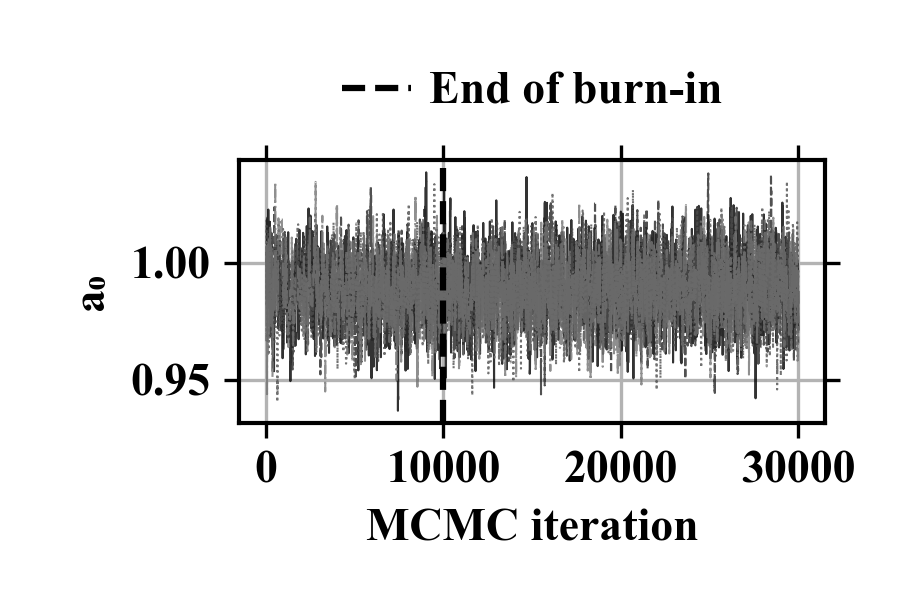

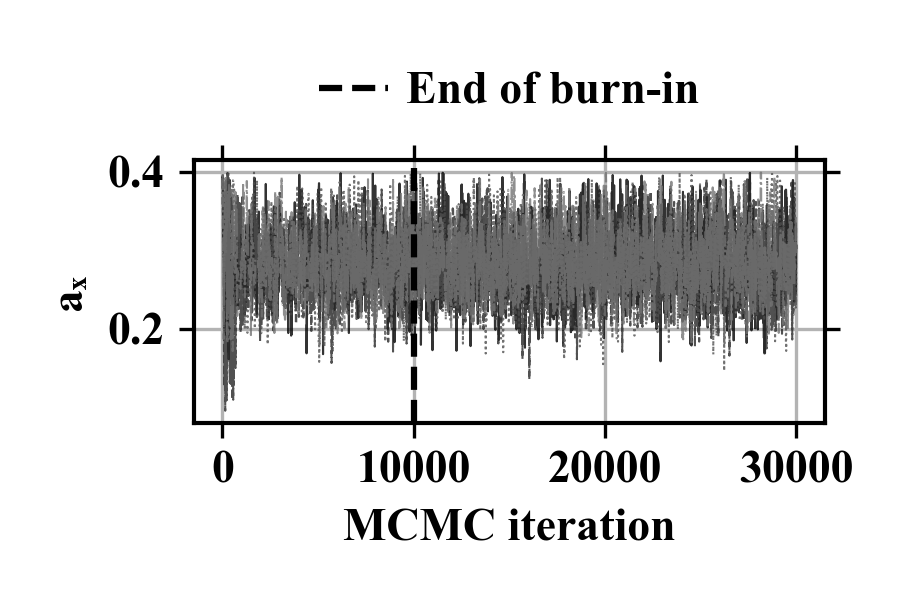

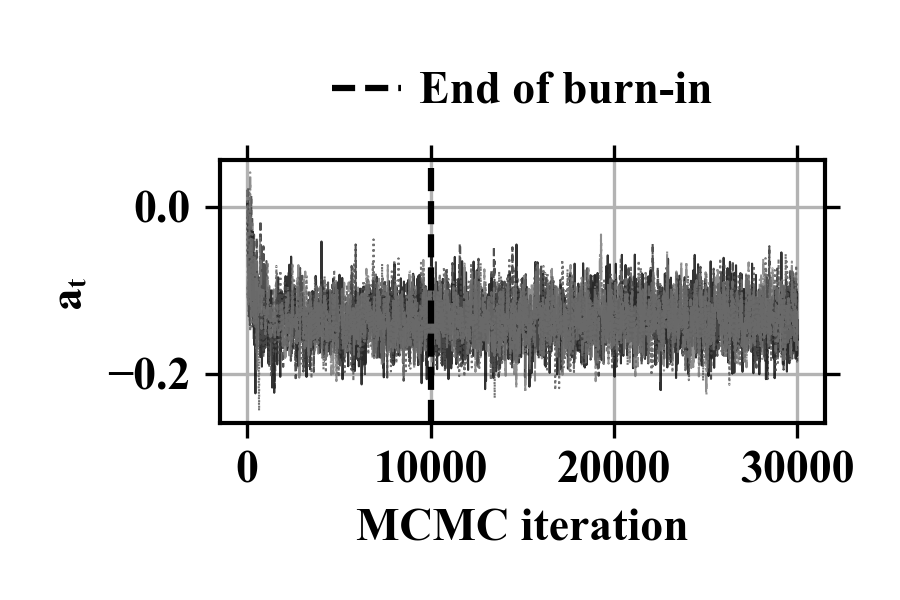

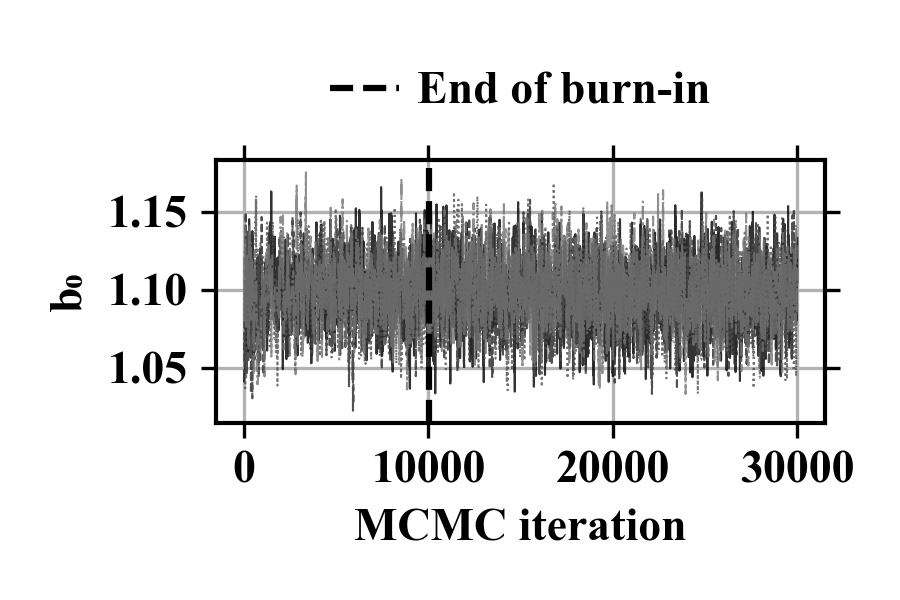

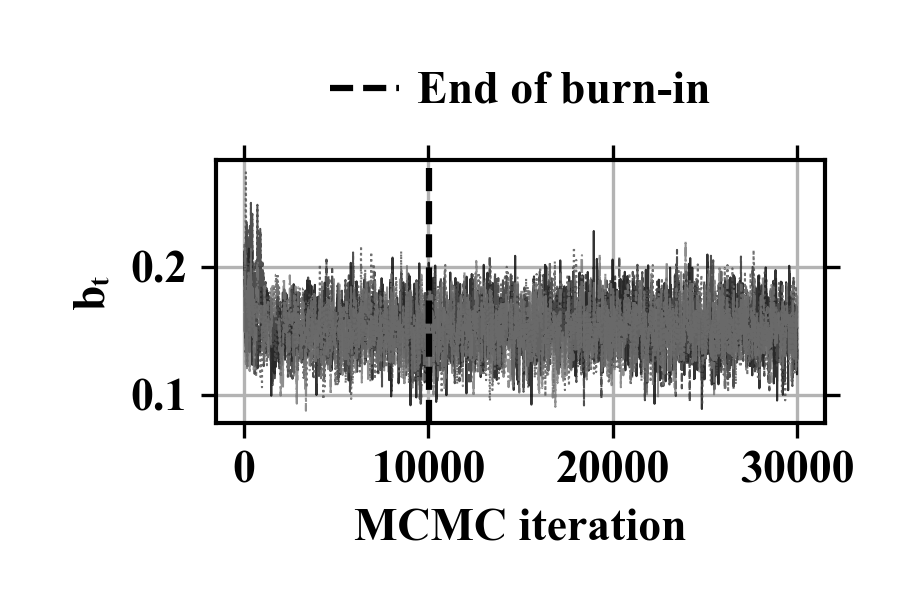

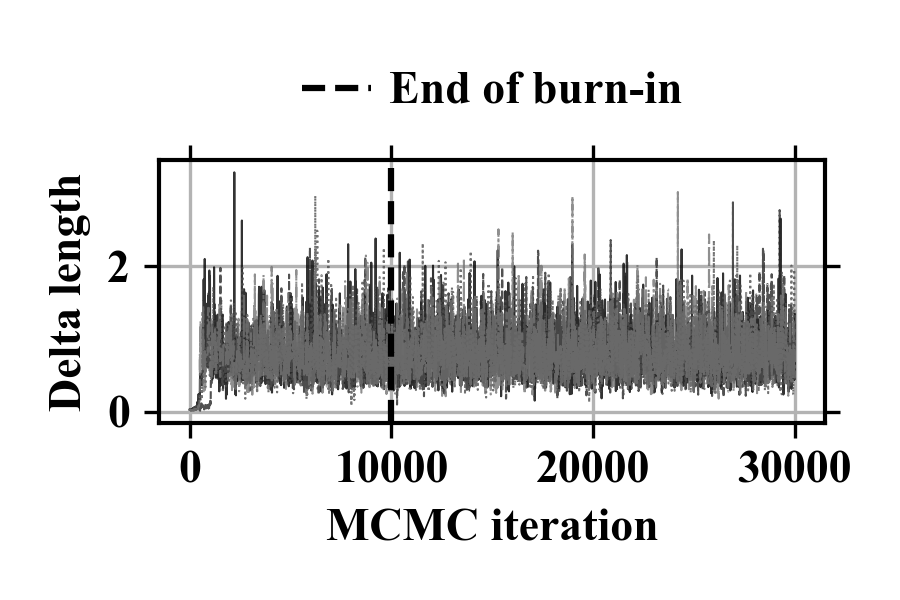

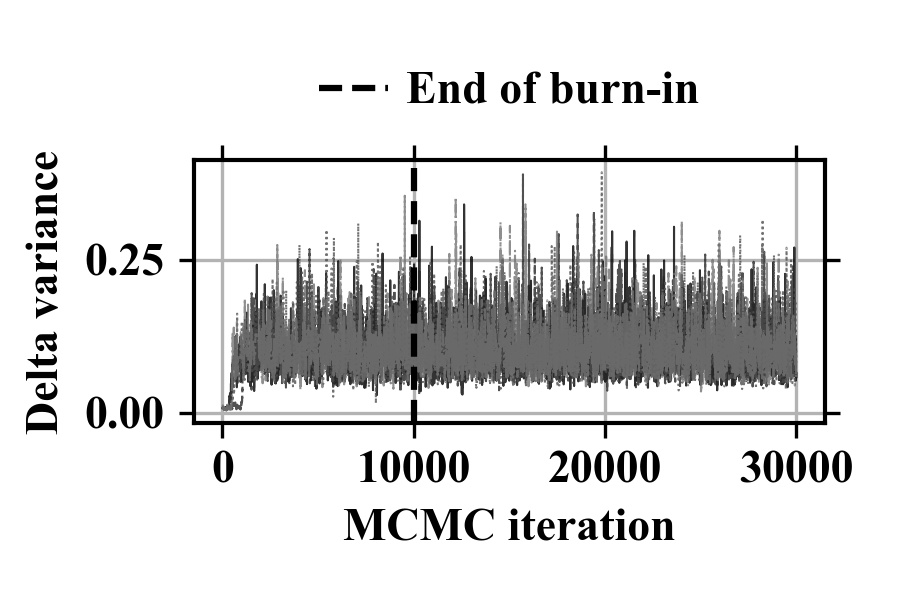

In [33]:
for j, label in enumerate(calibration_parameter_names):
    fig, ax = plt.subplots(figsize=(3, 2))
    for chain_id in range(n_chains):
        ax.plot(np.arange(1, n_calibration_steps+1), calibration_chains[chain_id, :, j], color=str(.15*chain_id), linestyle=trace_styles[chain_id], linewidth=.5, alpha=.8)
    ax.axvline(calibration_burn_in+.5, color='black', linestyle='--', label='End of burn-in')
    ax.set(xlabel='MCMC iteration', ylabel=label)
    figure_legend(ax, ncol=1)
    fig.tight_layout()
    plt.show()

JOINT POSTERIOR COMPONENTS: TWO EMULATOR CURVES AND ONE COMMON δ CURVE

In [35]:
def calibrated_components(trajectories_new, times_new, parameters):
    coefficients, lengthscale, variance = parameters[:5], parameters[5], parameters[6]
    specs = np.vstack((trajectory_obs, trajectories_new))
    times = np.r_[t_obs, times_new]
    x = input_trajectory(specs, times)
    mean, E = emulator_predict(specs, coefficients, times)
    C = common_discrepancy_covariance(x, times, x, times, lengthscale, variance, coefficients)
    n_obs_points, n_new = len(t_obs), len(times_new)
    n_obs = 2*n_obs_points
    observation_C = E[:n_obs, :n_obs] + shared_output_covariance(C[:n_obs_points, :n_obs_points]) + observation_noise_cov + calibration_jitter*np.eye(n_obs)
    L = cholesky(observation_C, lower=True, check_finite=False)
    # Targets: [eta1(t0),eta2(t0),..., common_delta(t0),common_delta(t1),...].
    cross_delta = np.repeat(C[:n_obs_points, n_obs_points:], 2, axis=0)
    cross = np.column_stack((E[:n_obs, n_obs:], cross_delta))
    prior_mean = np.r_[mean[n_obs:], np.zeros(n_new)]
    prior_C = np.zeros((3*n_new, 3*n_new))
    prior_C[:2*n_new, :2*n_new] = E[n_obs:, n_obs:]
    prior_C[2*n_new:, 2*n_new:] = C[n_obs_points:, n_obs_points:]
    v = solve_triangular(L, cross, lower=True, check_finite=False)
    residual = solve_triangular(L, y_obs-mean[:n_obs], lower=True, check_finite=False)
    posterior_C = prior_C-v.T@v
    return prior_mean+v.T@residual, (posterior_C+posterior_C.T)/2

def reality_prediction(trajectories_new, times_new, parameters, include_noise=True):
    mean, covariance = calibrated_components(trajectories_new, times_new, parameters)
    n = len(times_new)
    transform = np.column_stack((np.eye(2*n), np.repeat(np.eye(n), 2, axis=0)))
    mean, covariance = transform@mean, transform@covariance@transform.T
    if include_noise:
        covariance += np.diag(np.tile(sigma_obs**2, n))
    return mean, (covariance+covariance.T)/2

FOUR-PANEL FIGURES FOR y₁ AND y₂

Select one known input trajectory below. Each output gets a 6-by-4-inch figure:
prior code curves, posterior code curves, the common discrepancy, and reality prediction.
The discrepancy panel is intentionally the same for both outputs. The reality band
includes future sensor noise; the discrepancy band is a latent credible band.
All bands are pointwise 5th–95th percentiles in physical response units.

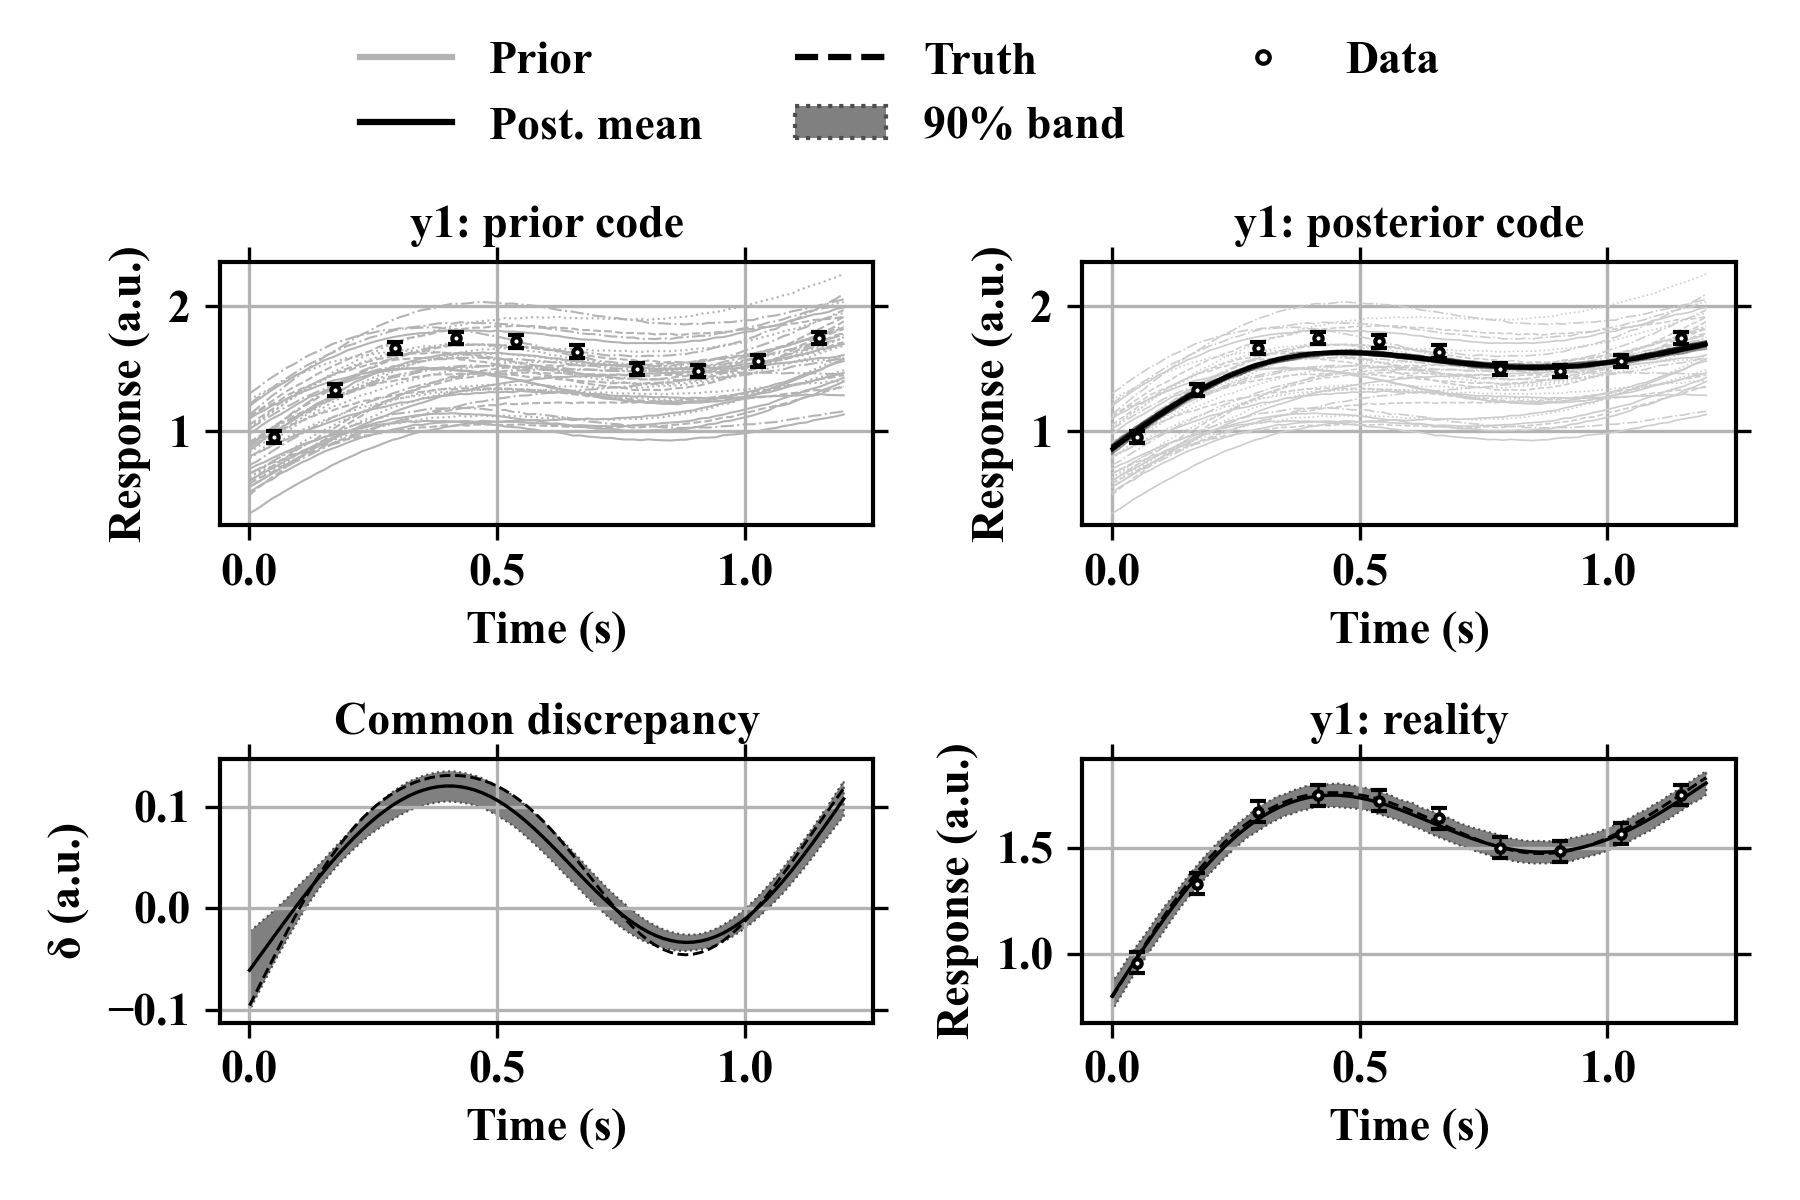

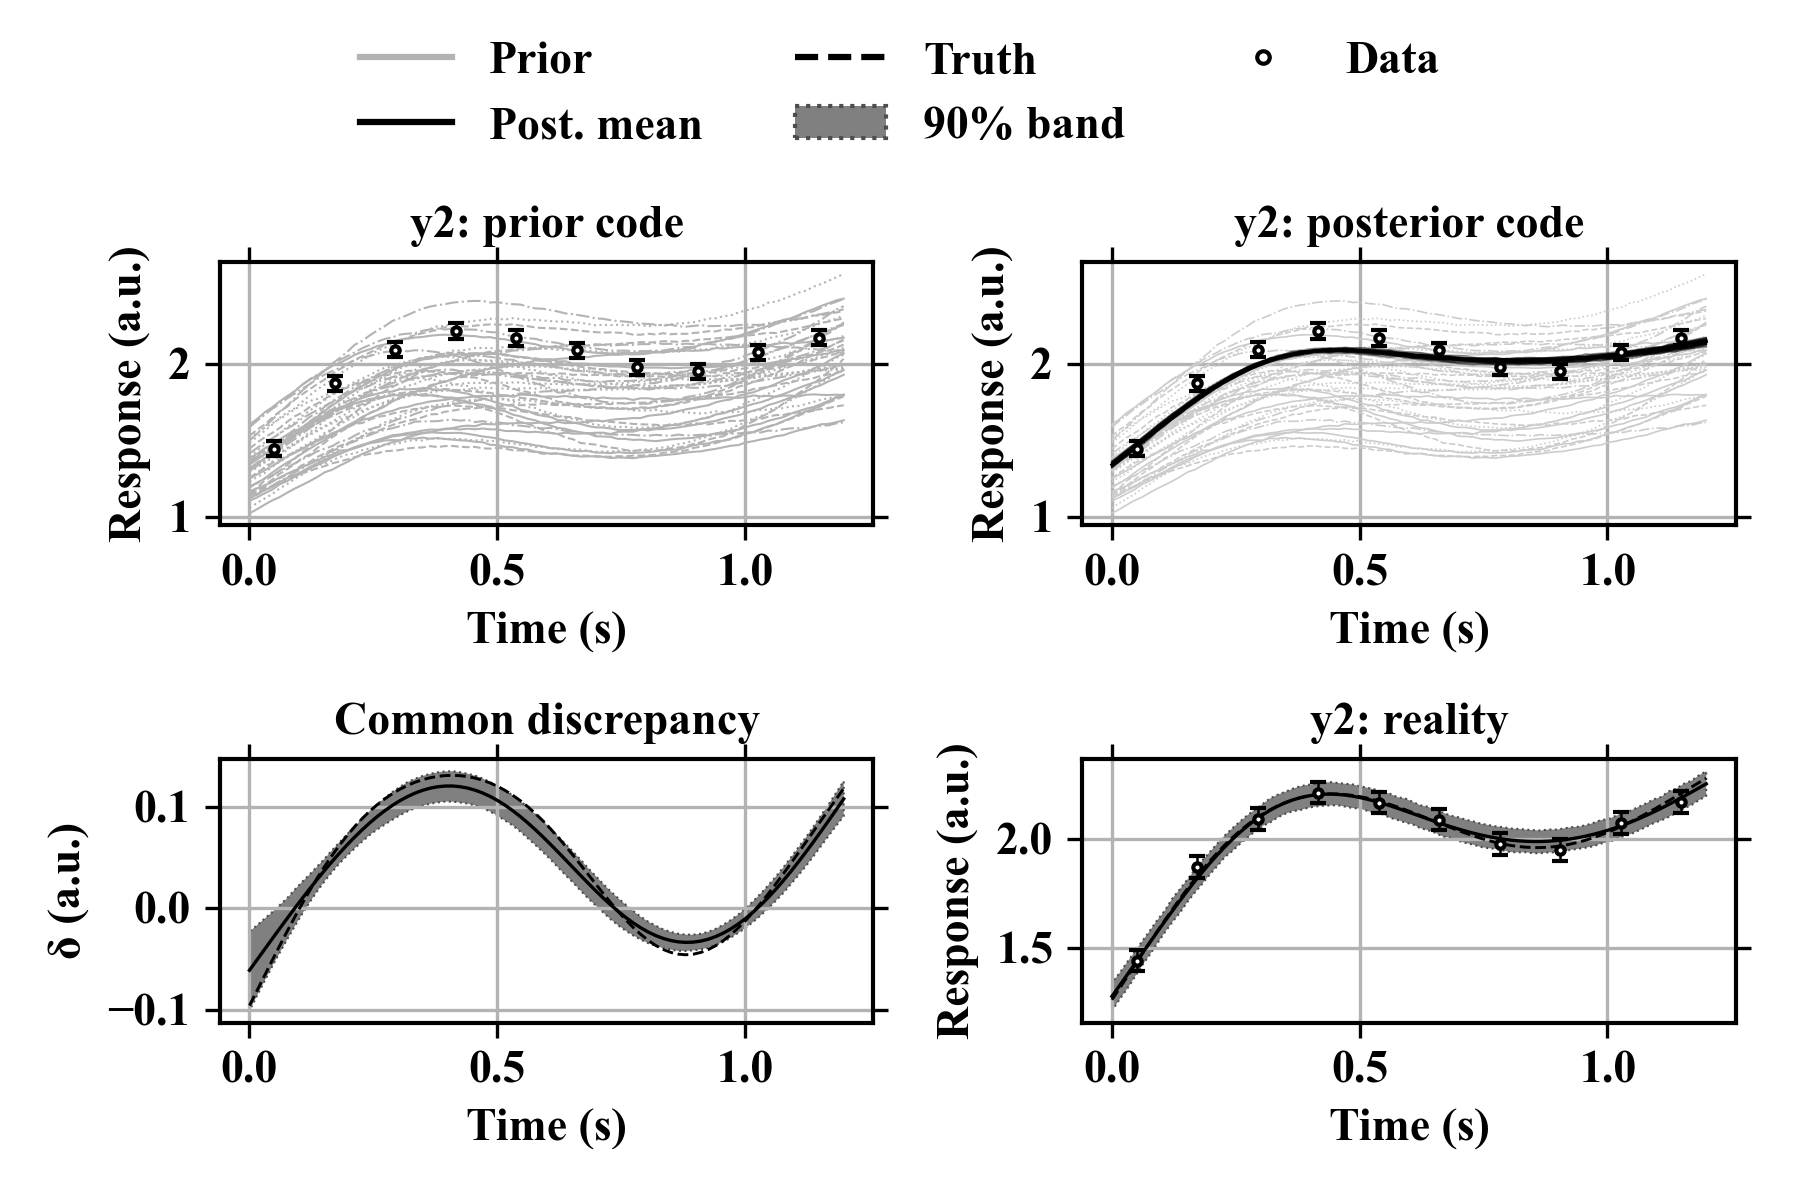

Mean prediction-band widths y1/y2: [0.10793094 0.10692969]


In [37]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
plot_trajectory_index = 0
trajectory_plot = observation_trajectories[plot_trajectory_index]
time_plot = np.linspace(0, T, 80)
trajectory_grid = np.repeat(trajectory_plot[None, :], len(time_plot), axis=0)
x_plot = input_trajectory(trajectory_grid, time_plot)
rng_prediction = np.random.default_rng(2028)
n_predictive_draws = min(1000, len(calibration_posterior_samples))
indices = rng_prediction.choice(len(calibration_posterior_samples), n_predictive_draws, replace=False)
eta_draws, delta_draws, reality_draws, eta_means, delta_means = [], [], [], [], []
prior_code_draws = []
with threadpool_limits(limits=1):
    for _ in range(40):
        coefficients = rng_prediction.uniform(coefficient_lower, coefficient_upper)
        mean, covariance = emulator_predict(trajectory_grid, coefficients, time_plot)
        prior_code_draws.append(draw_joint_normal(mean, covariance, rng_prediction).reshape(-1, 2))
    for index in indices:
        mean, covariance = calibrated_components(trajectory_grid, time_plot, calibration_posterior_samples[index])
        draw = draw_joint_normal(mean, covariance, rng_prediction)
        n = len(time_plot)
        eta = draw[:2*n].reshape(n, 2)
        delta = draw[2*n:]
        eta_draws.append(eta)
        delta_draws.append(delta)
        reality_draws.append(eta+delta[:, None]+rng_prediction.normal(size=(n, 2))*sigma_obs)
        eta_means.append(mean[:2*n].reshape(n, 2))
        delta_means.append(mean[2*n:])
eta_draws, delta_draws, reality_draws = map(np.asarray, (eta_draws, delta_draws, reality_draws))
eta_mean, delta_mean = np.mean(eta_means, axis=0), np.mean(delta_means, axis=0)
reality_mean = eta_mean+delta_mean[:, None]
delta_lower, delta_upper = np.percentile(delta_draws, [5, 95], axis=0)
reality_lower, reality_upper = np.percentile(reality_draws, [5, 95], axis=0)
selected_obs = np.all(trajectory_obs == trajectory_plot, axis=1)
common_truth = synthetic_discrepancy(x_plot, time_plot)
output_truth = physics_model(trajectory_grid, coefficients_true, time_plot)+common_truth[:, None]

for output in range(2):
    fig, axes = plt.subplots(2, 2, figsize=(6, 4))
    for curve in prior_code_draws:
        axes[0, 0].plot(time_plot, curve[:, output], color='0.7', linewidth=.5)
        axes[0, 1].plot(time_plot, curve[:, output], color='0.8', linewidth=.4)
    for curve in eta_draws[:40]:
        axes[0, 1].plot(time_plot, curve[:, output], 'k-', linewidth=.4, alpha=.4)
    axes[0, 1].plot(time_plot, eta_mean[:, output], 'k-', linewidth=.8)
    for ax in axes[0]:
        ax.errorbar(t_obs[selected_obs], y_obs_matrix[selected_obs, output], yerr=norm.ppf(.95)*sigma_obs[output], fmt='ko', markersize=2, markerfacecolor='white', capsize=2, linewidth=.6)
    axes[0, 0].set_title(f'y{output+1}: prior code')
    axes[0, 1].set_title(f'y{output+1}: posterior code')
    axes[1, 0].fill_between(time_plot, delta_lower, delta_upper, facecolor='0.5', edgecolor='0.3', linestyle=':', linewidth=.5)
    axes[1, 0].plot(time_plot, delta_mean, 'k-', linewidth=.8)
    axes[1, 0].plot(time_plot, common_truth, 'k--', linewidth=.7)
    axes[1, 0].set_title('Common discrepancy')
    axes[1, 1].fill_between(time_plot, reality_lower[:, output], reality_upper[:, output], facecolor='0.5', edgecolor='0.3', linestyle=':', linewidth=.5)
    axes[1, 1].plot(time_plot, reality_mean[:, output], 'k-', linewidth=.8)
    axes[1, 1].plot(time_plot, output_truth[:, output], 'k--', linewidth=.7)
    axes[1, 1].errorbar(t_obs[selected_obs], y_obs_matrix[selected_obs, output], yerr=norm.ppf(.95)*sigma_obs[output], fmt='ko', markersize=2, markerfacecolor='white', capsize=2, linewidth=.6)
    axes[1, 1].set_title(f'y{output+1}: reality')
    for ax in axes.ravel():
        ax.set(xlabel='Time (s)', ylabel='Response (a.u.)')
    axes[1, 0].set_ylabel('δ (a.u.)')
    handles = [Line2D([], [], color='0.7', label='Prior'), Line2D([], [], color='black', label='Post. mean'),
               Line2D([], [], color='black', linestyle='--', label='Truth'), Patch(facecolor='0.5', edgecolor='0.3', linestyle=':', label='90% band'),
               Line2D([], [], color='black', marker='o', markerfacecolor='white', linestyle='none', markersize=3, label='Data')]
    fig.legend(handles=handles, loc='upper center', ncol=3, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, .87))
    plt.show()
print('Mean prediction-band widths y1/y2:', (reality_upper-reality_lower).mean(axis=0))

THREE-PANEL FIGURES: θ₁(x,t) AND θ₂(t)

Each figure shows prior functions, posterior functions, posterior mean with a
pointwise 90% credible band.
θ₁ is evaluated along the selected known x(t) trajectory; θ₂ depends only on time.
These are uncertainty bands for the calibration functions, so measurement noise
is **not** added to them. There is no separate θ discrepancy in this model.

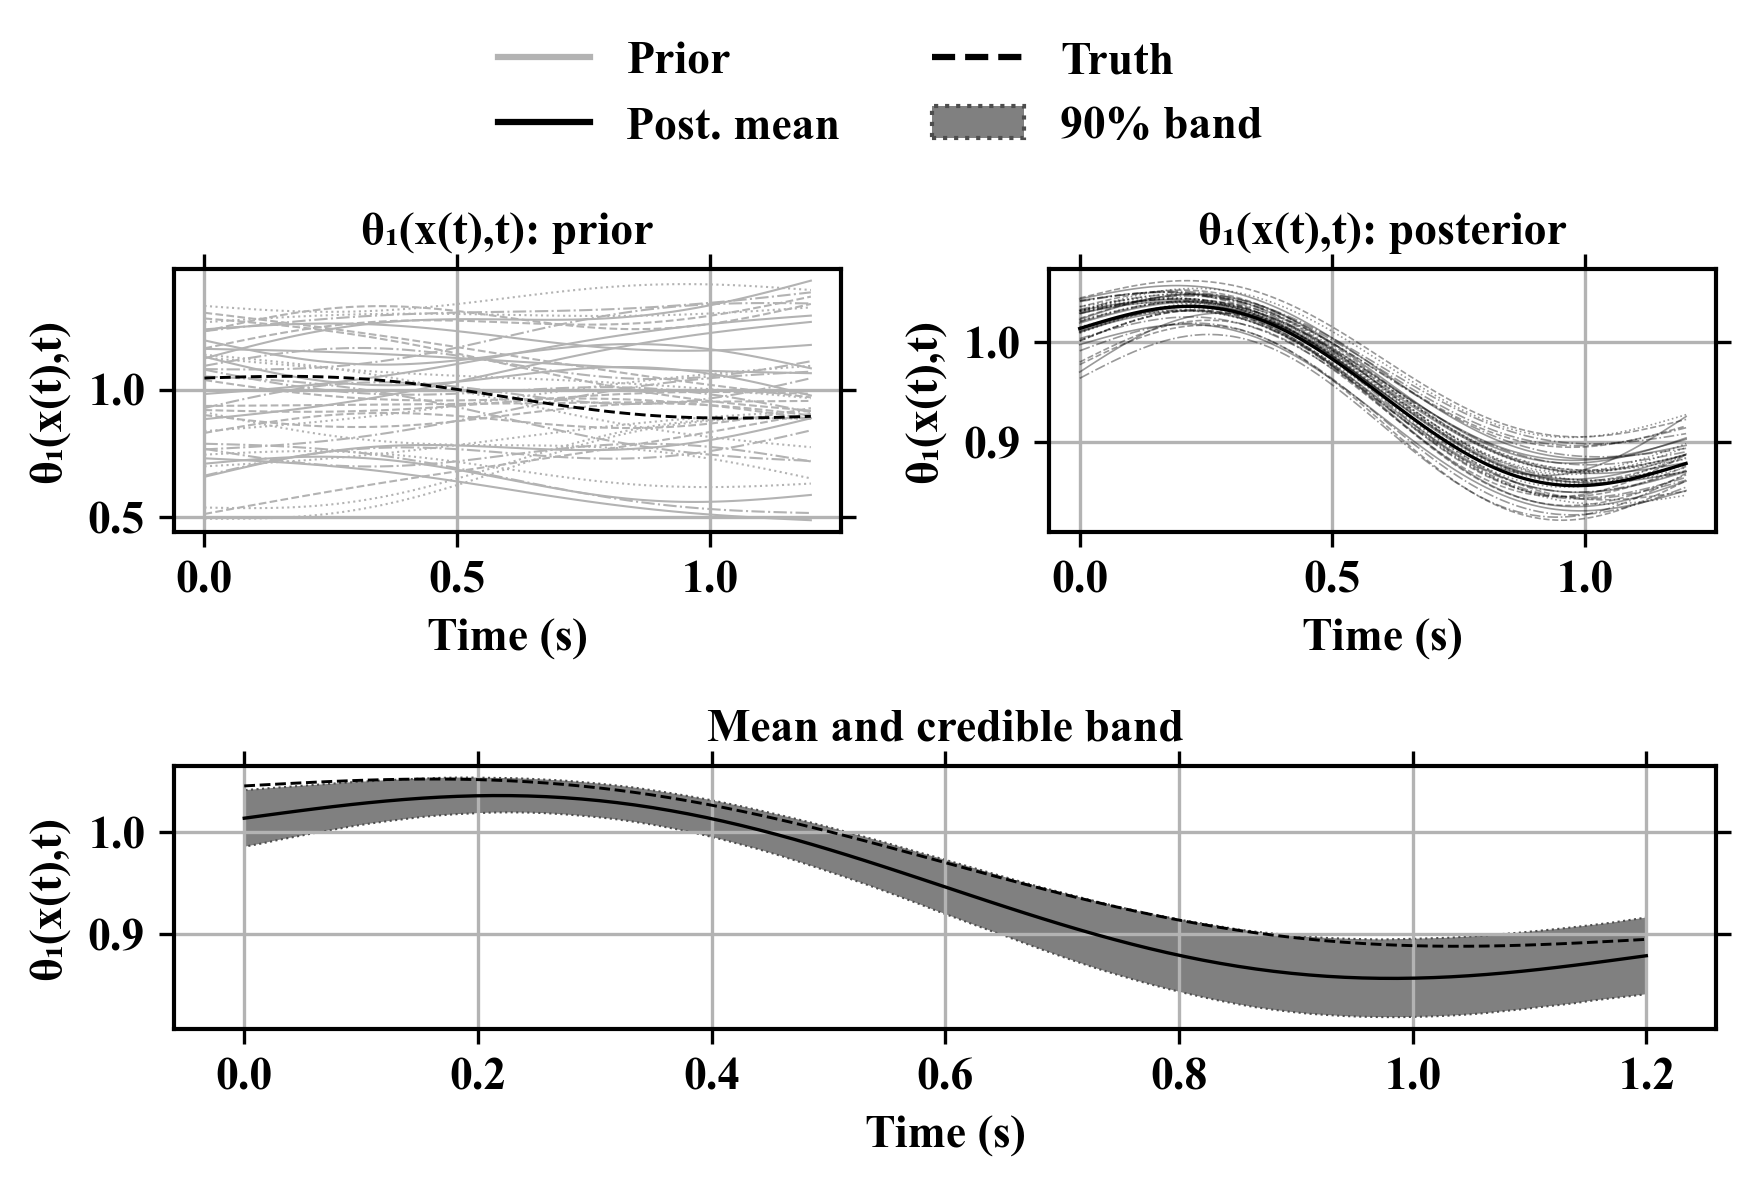

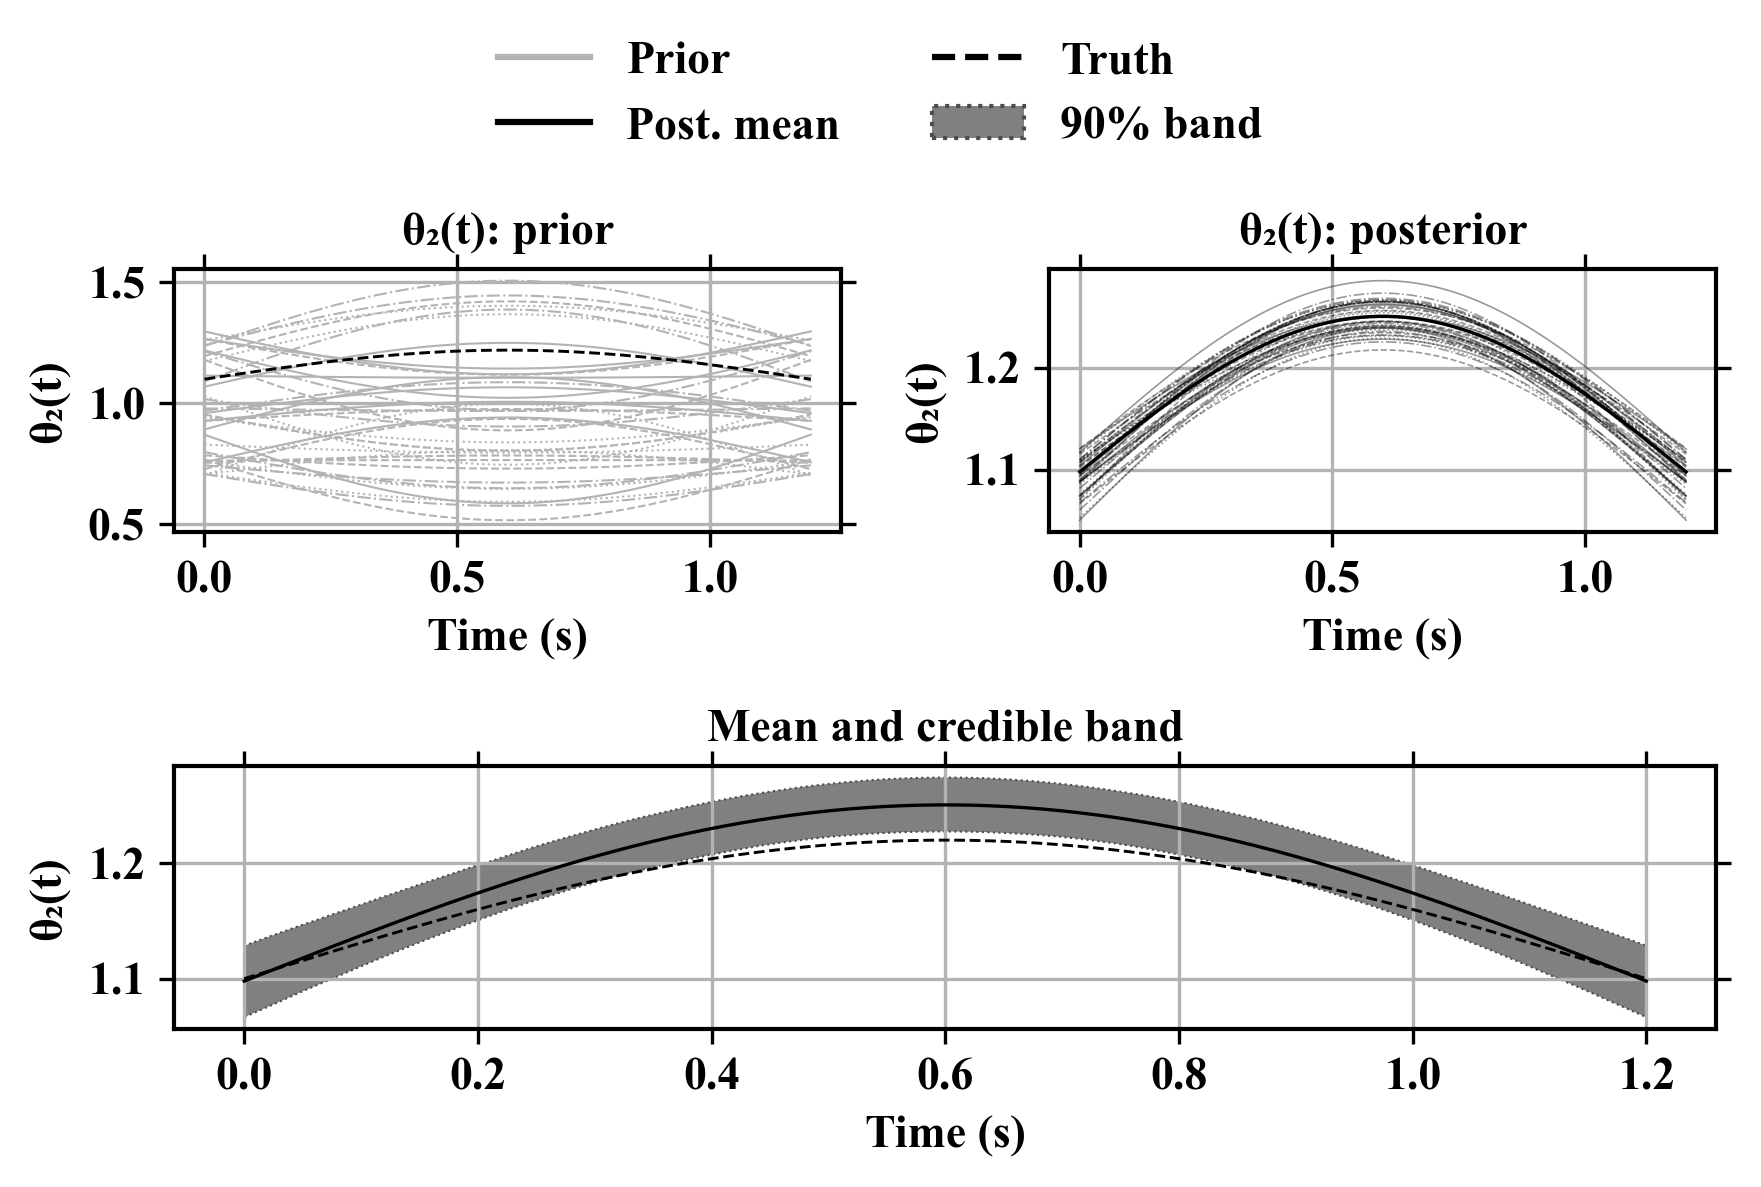

In [21]:
rng_theta = np.random.default_rng(2029)
theta_indices = rng_theta.choice(len(calibration_posterior_samples), min(4000, len(calibration_posterior_samples)), replace=False)
theta_posterior_functions = np.array([theta_functions(x_plot, time_plot, calibration_posterior_samples[i, :5]) for i in theta_indices])
theta_prior_functions = np.array([theta_functions(x_plot, time_plot, rng_theta.uniform(coefficient_lower, coefficient_upper)) for _ in range(40)])
theta_true_functions = np.array(theta_functions(x_plot, time_plot, coefficients_true))
theta_function_results = []
for j, name in enumerate(['θ₁(x(t),t)', 'θ₂(t)']):
    functions = theta_posterior_functions[:, j, :]
    mean = functions.mean(axis=0)
    lower, upper = np.percentile(functions, [5, 95], axis=0)
    truth = theta_true_functions[j]
    theta_function_results.append(dict(mean=mean, lower=lower, upper=upper, truth=truth))
    fig = plt.figure(figsize=(6, 4))
    grid = fig.add_gridspec(2, 2)
    axes = [fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[0, 1]),
            fig.add_subplot(grid[1, :])]
    for curve in theta_prior_functions[:, j, :]:
        axes[0].plot(time_plot, curve, color='0.7', linewidth=.5)
    for curve in functions[:40]:
        axes[1].plot(time_plot, curve, color='black', linewidth=.4, alpha=.4)
    axes[0].plot(time_plot, truth, 'k--', linewidth=.7)
    axes[1].plot(time_plot, mean, 'k-', linewidth=.8)
    axes[0].set_title(f'{name}: prior')
    axes[1].set_title(f'{name}: posterior')
    axes[2].fill_between(time_plot, lower, upper, facecolor='0.5', edgecolor='0.3', linestyle=':', linewidth=.5)
    axes[2].plot(time_plot, mean, 'k-', linewidth=.8)
    axes[2].plot(time_plot, truth, 'k--', linewidth=.7)
    axes[2].set_title('Mean and credible band')
    for ax in axes:
        ax.set(xlabel='Time (s)', ylabel=name)
    handles = [Line2D([], [], color='0.7', label='Prior'), Line2D([], [], color='black', label='Post. mean'),
               Line2D([], [], color='black', linestyle='--', label='Truth'), Patch(facecolor='0.5', edgecolor='0.3', linestyle=':', label='90% band')]
    fig.legend(handles=handles, loc='upper center', ncol=2, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, .87))
    plt.show()

VALIDATION: UNITS, SHARED DISCREPANCY, FUNCTION DEPENDENCE AND COVARIANCE

In [41]:
check_t = np.array([.15, .55, .95])
check_specs = np.repeat(trajectory_plot[None, :], len(check_t), axis=0)
check_x = input_trajectory(check_specs, check_t)
parameters = calibration_posterior_samples.mean(axis=0)
latent_mean, latent_cov = reality_prediction(check_specs, check_t, parameters, False)
noisy_mean, noisy_cov = reality_prediction(check_specs, check_t, parameters, True)
np.testing.assert_allclose(latent_mean, noisy_mean)
np.testing.assert_allclose(noisy_cov-latent_cov, np.diag(np.tile(sigma_obs**2, len(check_t))), atol=1e-10)
assert np.linalg.eigvalsh(noisy_cov).min() >= -1e-8

# The common discrepancy cancels in y1-y2, including its variance.
C = common_discrepancy_covariance(check_x, check_t, check_x, check_t, parameters[5], parameters[6], parameters[:5])
contrast = np.kron(np.eye(len(check_t)), np.array([[1., -1.]]))
np.testing.assert_allclose(contrast@shared_output_covariance(C)@contrast.T, 0, atol=1e-10)
np.testing.assert_allclose(theta_functions(check_x, check_t, parameters[:5])[1], theta_functions(check_x+.1, check_t, parameters[:5])[1])

# Finite-difference check of the frozen emulator mean derivatives.
analytic = emulator_coefficient_gradient(check_specs, parameters[:5], check_t)
for j in range(5):
    step = 1e-4*(coefficient_upper[j]-coefficient_lower[j])
    shift = np.eye(5)[j]*step
    plus = emulator_predict(check_specs, parameters[:5]+shift, check_t)[0]
    minus = emulator_predict(check_specs, parameters[:5]-shift, check_t)[0]
    np.testing.assert_allclose(analytic[:, :, j], ((plus-minus)/(2*step)).reshape(-1, 2), rtol=3e-3, atol=3e-5)
assert np.array_equal(frozen_before_calibration, frozen_emulator[0])
print('Checks passed: SVD scaling, common-delta cancellation, sensor-noise variance, theta2 time-only dependence, and emulator derivatives.')
print('Maximum R-hat: emulator / calibration:', emulator_diagnostics.R_hat.max(), calibration_diagnostics.R_hat.max())
print('Retained draws per chain:', n_steps-burn_in, n_calibration_steps-calibration_burn_in)

Checks passed: SVD scaling, common-delta cancellation, sensor-noise variance, theta2 time-only dependence, and emulator derivatives.
Maximum R-hat: emulator / calibration: 1.0036910557999301 1.0037497409532636
Retained draws per chain: 20000 20000
